# 自研方法：推理路径、消融与主表（代码 + 实际输出）
Our two-stage method: reasoning chain, ablation, main table (code + real output)

每一步回答一个问题："为什么要这样设计？"并用一个实验给出证据。
Each step answers one design question and backs it with an experiment.

**数据来源 / Sources**
- 代码：实验一求解器 v2（`bench/`、`baselines/`、`flp/`），与 `CODE_MD5_v2.txt` 一致，**未改动**。
- 原始结果：Mac `~/FLP/results/bench` 与 `bench2` 的每次运行文件（10 个种子；论文表用的就是这些）。
- 标"现场运行"的格子是今天在云端容器里重新跑的（机器比原实验慢，只用来演示机制，不替代论文数字）。

| 步 / Step | 问题 / Question | 证据 / Evidence |
|---|---|---|
| R1 | 为什么不用精确方法？ | 网格格子数算术 + 论文 MINLP 行 |
| R2 | 第一阶段为什么用切片树？ | 解码一个基因，检查面积 |
| R3 | 切片树的天花板在哪？ | O7：所有切片类方法都停在 131.6892 |
| R4 | 第二阶段为什么是序列对 + SOCP？ | 现场抛光 + 重算 polish 行 |
| R5 | 第二阶段为什么要搜索、何时只抛光？ | 每次运行的两阶段成本、SOCP 次数与耗时、收敛曲线 |
| R6 | 精英池和近邻移动有用吗？ | 消融 |
| A | 消融全表 + 显著性检验 | 原始数据重算 |
| T | 主表 | 原始数据重算 |

In [1]:
# 0 · 设置 / Setup
import json, glob, os, sys, time, collections, re
import numpy as np, pandas as pd
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import display, Image
plt.rcParams["font.sans-serif"] = ["Noto Sans CJK SC", "DejaVu Sans"]; plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.width", 200)

ROOT   = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))   # 仓库根目录 / repo root
SOLVER = ROOT                                  # 实验一代码 v2（bench/ baselines/ flp/，未改动）
RAW    = os.path.join(ROOT, "results")         # 每次运行的原始结果（来自 Mac ~/FLP/results）
PAPER  = os.path.join(ROOT, "paper", "benchmark_v1")
FIG    = os.path.join(os.getcwd(), "fig"); os.makedirs(FIG, exist_ok=True)
sys.path.insert(0, SOLVER); os.chdir(SOLVER)
from flp.instance import load
from flp.evaluate import evaluate
from bench.common import problem
from baselines.cro_sts import sts
from bench.socp import from_problem, rects_to_sp, sp_relations, reduce_relations

INST = ["O7", "vC10a", "AB20", "SC30", "Du62"]
REF  = {"O7": 131.6531381, "vC10a": 18522.79, "AB20": 5021.17, "SC30": 3343.47, "Du62": 3635307.30}

# 原始结果：同一 (方法, 实例) 若在 bench2 里有重跑，用 bench2（论文表的取法）
def load_raw():
    R = {}
    for d in ["bench", "bench2"]:
        tmp = collections.defaultdict(list)
        for f in glob.glob(f"{RAW}/{d}/*_s*.json"):
            r = json.load(open(f)); tmp[(r["method"], r["instance"])].append(r)
        R.update(tmp)
    return {k: sorted(v, key=lambda r: r["seed"]) for k, v in R.items()}
RUNS = load_raw()
print("原始运行文件:", sum(len(v) for v in RUNS.values()), "个；(方法, 实例) 组合:", len(RUNS))
print(sorted({m for m, _ in RUNS}))

原始运行文件: 445 个；(方法, 实例) 组合: 49
['construct', 'cro', 'ga', 'ours', 'ours_noelite', 'ours_nos1', 'ours_s1', 'ours_s2', 'ours_unif', 'sa', 'swap']


## 数据：5 个基准和目标函数 / Data
目标函数（所有方法相同，由独立检查器计算）：

$$C=\sum_{i<j} w_{ij}\,\big(|c^x_i-c^x_j|+|c^y_i-c^y_j|\big),\quad c=\text{矩形中心}$$

约束：面积 $w_ih_i\ge A_i$；长宽比 $\max(w_i/h_i,h_i/w_i)\le\alpha$；在厂房内；两两不重叠。

In [2]:
# 1 · 实例 / instances
rows = []
for k in INST:
    I = load(k)
    rows.append(dict(实例=k, n=I.n, W=I.W, H=I.H, alpha=I.shape_value, 填充率=f"{I.areas.sum()/(I.W*I.H):.2%}",
                     有流量的对=int((np.triu(I.w, 1) > 0).sum()), 参考值=REF[k]))
display(pd.DataFrame(rows).set_index("实例"))
I = load("O7")
print("O7 面积 A =", I.areas.tolist())
print("O7 权重矩阵 w（对称，成本按 i<j 求和）:")
display(pd.DataFrame(I.w.astype(int), index=range(1, 8), columns=range(1, 8)))

,n,W,H,alpha,填充率,有流量的对,参考值
实例,,,,,,,
O7,7,8.540,13.000,4.0,99.98%,10,1.316531e+02
vC10a,10,25.000,51.000,5.0,100.00%,12,1.852279e+04
AB20,20,30.000,20.000,4.0,100.00%,62,5.021170e+03
SC30,30,15.000,12.000,5.0,90.56%,50,3.343470e+03
Du62,62,117.124,117.124,4.0,100.00%,1182,3.635307e+06


O7 面积 A = [16.0, 16.0, 16.0, 36.0, 9.0, 9.0, 9.0]
O7 权重矩阵 w（对称，成本按 i<j 求和）:


,1,2,3,4,5,6,7
1,0,0,0,5,0,0,1
2,0,0,0,3,0,0,1
3,0,0,0,2,0,0,1
4,5,3,2,0,4,4,0
5,0,0,0,4,0,0,2
6,0,0,0,4,0,0,1
7,1,1,1,0,2,1,0


## R1 · 为什么不用精确方法？ / Why not an exact method?
**推论**：精确模型在这些实例上要么规模太大、要么离散化后根本没有可行解，所以核心必须是启发式搜索；精确数学只用在"给定拓扑后的几何"上（见 R4）。
**Claim**: exact models either do not scale or become infeasible once discretised, so the core must be a heuristic search; exact math is used only for geometry under a fixed topology (R4).

In [3]:
# 2 · 网格 CP-SAT：格子数够不够？ / grid CP-SAT cell balance (bench/methods/cpsat.py 的离散化规则)
import math
rows = []
for k, s in [("O7", 10), ("vC10a", 10), ("AB20", 10), ("SC30", 10), ("Du62", 1)]:
    I = load(k)
    have = math.floor(I.W * s + 1e-9) * math.floor(I.H * s + 1e-9)          # 厂房向下取整后的格子数
    need = sum(math.ceil(a * s * s - 1e-9) for a in I.areas)               # 每个部门面积向上取整后的格子数
    rows.append(dict(实例=k, 格距=f"1/{s}", 厂房格子=have, 部门需要=need, 差=have - need, 可行="否" if need > have else "可能"))
display(pd.DataFrame(rows).set_index("实例"))

,格距,厂房格子,部门需要,差,可行
实例,,,,,
O7,1/10,11050,11100,-50,否
vC10a,1/10,127500,127500,0,可能
AB20,1/10,60000,60000,0,可能
SC30,1/10,18000,16300,1700,可能
Du62,1/1,13689,13718,-29,否


In [4]:
# 3 · 论文里 300 s 精确凸 MINLP 的结果（原始文件不在 Mac 上，只能读论文表）/ MINLP rows from the paper table
tab = open(f"{PAPER}/tables/tab_main.tex").read()
for blk in re.split(r"\\multicolumn\{6\}\{l\}\{\\textit\{", tab)[1:]:
    name = blk.split("}")[0]
    line = [l for l in blk.splitlines() if l.strip().startswith("\\quad MINLP")][0]
    print(f"{name:6s}", re.sub(r"\\quad |\\\\|\{,\}", lambda m: "," if m.group(0) == "{,}" else "", line).strip())

O7     MINLP & 1/1 & 131.6531 & 131.6531 & 0.000 & 0.000
vC10a  MINLP & 1/1 & 22,430.69 & 22,430.69 & 21.10 & 21.10
AB20   MINLP & 0/1 & -- & -- & -- & --
SC30   MINLP & 1/1 & 10,073.72 & 10,073.72 & 201.30 & 201.30
Du62   MINLP & 0/1 & -- & -- & -- & --


## R2 · 第一阶段为什么用切片树（STS）？ / Why a slicing tree for Stage 1?
切片树基因 = 部门序列 `seq` + 切割顺序 `cuts` + 切割方向 `codes`。每一刀**按两边面积比例**切当前矩形，所以：每个部门得到的面积和需求成同一比例（厂房正好等于面积和时就是精确相等）、厂房天然铺满、永远不重叠。唯一可能违反的是长宽比，用罚分处理：

$$\text{fitness}=C+\pi\cdot\sum_i\max(0,\ r_i-\alpha),\qquad \pi=0.05\,\Big(\sum_{i<j}w_{ij}\Big)(W+H)$$

**推论**：搜索空间里每个点都是"几乎可行"的布局，SA 可以很快地在里面走。

In [5]:
# 4 · 解码一个随机基因（O7）/ decode a random genome
P = problem("O7"); rng = np.random.default_rng(1)
seq = rng.permutation(P.n_d).astype(np.int64); cuts = rng.permutation(P.n_d - 1).astype(np.int64)
codes = rng.integers(0, 4, P.n_d - 1).astype(np.int64)
print("seq =", (seq + 1).tolist(), " cuts =", cuts.tolist(), " codes =", codes.tolist(), "(0 横 1 竖 2 反横 3 反竖)")
Rr = sts.decode(seq, cuts, codes, P.areas_d, P.W, P.H)
D = pd.DataFrame(Rr, columns=["x", "y", "w", "h"], index=range(1, P.n + 1)).round(4)
D["w·h"] = (D.w * D.h).round(4); D["A"] = P.areas; D["长宽比"] = np.maximum(D.w / D.h, D.h / D.w).round(3)
display(D)
fit, cost, ex, ninf = sts.evaluate(seq, cuts, codes, P.areas_d, P.W, P.H, P.Wt_d, P.alpha_d, P.pen, 0.0)
ratio = (Rr[:, 2] * Rr[:, 3]) / P.areas
print(f"每个部门 w·h / A = {ratio.min():.6f} … {ratio.max():.6f}（全部相同 = 厂房面积 / 部门面积和 = {P.W*P.H/P.areas.sum():.6f}）")
print(f"铺满厂房: {np.isclose((Rr[:, 2]*Rr[:, 3]).sum(), P.W*P.H)} | 两两不重叠、在厂房内: {not [v for v in evaluate(P.inst, [tuple(r) for r in Rr])['violations'] if v[0] in ('overlap', 'outside')]}")
print(f"成本 C = {cost:.4f} | 长宽比超出合计 = {ex:.4f}（{ninf} 个部门超限） | 罚分系数 π = {P.pen:.2f} | fitness = {fit:.4f}")

seq = [6, 1, 2, 5, 3, 7, 4]  cuts = [1, 5, 2, 3, 4, 0]  codes = [2, 2, 0, 0, 3, 3] (0 横 1 竖 2 反横 3 反竖)


,x,y,w,h,w·h,A,长宽比
1,0.0000,0.0000,5.4656,2.9279,16.0027,16.0,1.867
2,0.0000,6.9099,8.5400,1.8739,16.0031,16.0,4.557
3,3.0744,2.9279,5.4656,2.9279,16.0027,16.0,1.867
4,0.0000,8.7838,8.5400,4.2162,36.0063,36.0,2.026
5,0.0000,5.8559,8.5400,1.0541,9.0020,9.0,8.102
6,5.4656,0.0000,3.0744,2.9279,9.0015,9.0,1.050
7,0.0000,2.9279,3.0744,2.9279,9.0015,9.0,1.050


每个部门 w·h / A = 1.000180 … 1.000180（全部相同 = 厂房面积 / 部门面积和 = 1.000180）
铺满厂房: True | 两两不重叠、在厂房内: True
成本 C = 179.1365 | 长宽比超出合计 = 4.6595（2 个部门超限） | 罚分系数 π = 25.85 | fitness = 299.5741


## R3 · 切片树的天花板 / The ceiling of slicing trees
**推论**：切片树只能表示"一刀一刀切出来"的布局。O7 的已证明最优布局不是切片布局，所以**所有基于切片树的方法都到不了最优**——不管搜得多好。
**Claim**: slicing trees only represent guillotine layouts. The proven O7 optimum is not one, so every slicing-based method stops short of it, however well it searches.

In [6]:
# 5 · O7：各方法 10 次运行的最好与最差 / O7, best and worst of 10 runs
rows = []
for m, lab in [("swap", "Swap（切片）"), ("ga", "GA（切片）"), ("sa", "SA（切片）"), ("cro", "CRO（切片）"),
               ("ours_s1", "Ours 只第一阶段（切片）"), ("ours_s2", "第一阶段 + 一次 SOCP"), ("ours", "Ours 完整")]:
    c = np.array([r["cost"] for r in RUNS[(m, "O7")] if r["feasible"]])
    rows.append(dict(方法=lab, 可行=f"{len(c)}/10", 最好=round(c.min(), 4), 最差=round(c.max(), 4),
                     最好差距=f"{100*(c.min()-REF['O7'])/REF['O7']:.3f}%"))
display(pd.DataFrame(rows).set_index("方法"))
print("O7 已证明最优（MINLPLib）=", REF["O7"])

,可行,最好,最差,最好差距
方法,,,,
Swap（切片）,10/10,131.6892,131.6892,0.027%
GA（切片）,10/10,131.6892,144.9556,0.027%
SA（切片）,10/10,131.6892,131.6892,0.027%
CRO（切片）,10/10,131.6892,131.6892,0.027%
Ours 只第一阶段（切片）,10/10,131.6892,131.6892,0.027%
第一阶段 + 一次 SOCP,10/10,131.6532,131.6604,0.000%
Ours 完整,10/10,131.6532,131.6532,0.000%


O7 已证明最优（MINLPLib）= 131.6531381


## R4 · 第二阶段为什么是序列对 + SOCP？ / Why sequence pair + SOCP for Stage 2?
序列对 $(\Gamma^+,\Gamma^-)$（Murata 等 1996）给每一对部门定一个"左/右"或"上/下"关系，**包括非切片布局**。关系一旦固定，剩下的几何问题是凸的：

$$\min \sum_{i<j} w_{ij}(d^x_{ij}+d^y_{ij})\ \text{s.t.}\ d^x_{ij}\ge\pm(x_i-x_j),\ x_i+\tfrac{w_i}{2}\le x_j-\tfrac{w_j}{2}\ (i\text{ 在 }j\text{ 左}),\ \ldots,\ \|(w_i-h_i,\,2\sqrt{A_i})\|_2\le w_i+h_i$$

最后一个约束是旋转二阶锥，等价于 $w_ih_i\ge A_i$——面积精确，没有近似。所以**给定拓扑，SOCP 直接给出这个拓扑下的最优尺寸和位置**（Clarabel 求解，见 `bench/socp.py`）。
**推论**：把第一阶段的布局转成序列对再解一次 SOCP，只会变好、不会变差（起点本身就满足这些关系）。

Γ+ = [2, 1, 4, 3, 5, 7, 6]  Γ- = [3, 6, 7, 2, 5, 4, 1]
关系：左右 6 对、上下 15 对（合计 21 = 7·6/2）；传递约简后进模型 13 条
第一阶段 131.6892 → SOCP 131.6532（3 ms，状态 Solved）；独立检查器可行: True
与已证明最优 131.6531381 的差: 0.00003%


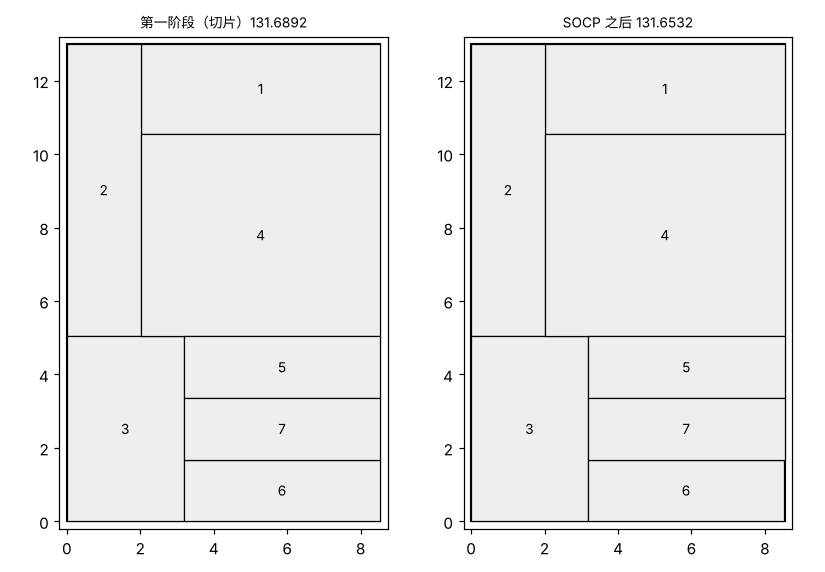

In [7]:
# 6 · 现场：把 O7 第一阶段的最好布局交给 SOCP / live: polish the best Stage-1 layout on O7
P = problem("O7"); S2 = from_problem(P)
r0 = min(RUNS[("ours_s1", "O7")], key=lambda r: r["cost"])
R0 = np.array(r0["rects"])
gp, gm = rects_to_sp(R0)
Lf, Bf = sp_relations(gp, gm, reduce=False); L, B = reduce_relations(Lf, Bf)
print("Γ+ =", (gp + 1).tolist(), " Γ- =", (gm + 1).tolist())
print(f"关系：左右 {int(Lf.sum())} 对、上下 {int(Bf.sum())} 对（合计 {int(Lf.sum()+Bf.sum())} = 7·6/2）；传递约简后进模型 {int(L.sum()+B.sum())} 条")
t = time.time(); o = S2.solve_sp(gp, gm); dt = time.time() - t
ev0 = evaluate(P.inst, [tuple(r) for r in R0]); ev1 = evaluate(P.inst, [tuple(r) for r in o["rects"]])
print(f"第一阶段 {ev0['cost']:.4f} → SOCP {ev1['cost']:.4f}（{dt*1e3:.0f} ms，状态 {o['status']}）；独立检查器可行: {ev1['feasible']}")
print(f"与已证明最优 {REF['O7']} 的差: {100*(ev1['cost']-REF['O7'])/REF['O7']:.5f}%")
fig, axs = plt.subplots(1, 2, figsize=(7.5, 5.2), dpi=110)
for ax, RR, tt in [(axs[0], R0, f"第一阶段（切片）{ev0['cost']:.4f}"), (axs[1], o["rects"], f"SOCP 之后 {ev1['cost']:.4f}")]:
    ax.add_patch(Rectangle((0, 0), P.W, P.H, fill=False, lw=1.4))
    for k, (x, y, w, h) in enumerate(RR, 1):
        ax.add_patch(Rectangle((x, y), w, h, fc="#eeeeee", ec="black", lw=0.8)); ax.text(x + w/2, y + h/2, str(k), ha="center", va="center", fontsize=9)
    ax.set_xlim(-0.2, P.W + 0.2); ax.set_ylim(-0.2, P.H + 0.2); ax.set_aspect("equal"); ax.set_title(tt, fontsize=9)
fig.tight_layout(); fig.savefig(f"{FIG}/o7_polish.png"); plt.close(fig); display(Image(f"{FIG}/o7_polish.png"))

In [8]:
# 7 · 重算论文缺原始数据的两行："SA + polish" 和 "CRO + polish" / regenerate the polish rows
def polish(rects, P, S2):
    R = np.array(rects)[:P.n]
    o = S2.solve_sp(*rects_to_sp(R))
    if o["rects"] is None or not np.isfinite(o["cost"]): return R
    ev = evaluate(P.inst, [tuple(r) for r in o["rects"]])
    c0 = evaluate(P.inst, [tuple(r) for r in R])["cost"]
    return o["rects"] if ev["feasible"] and ev["cost"] < c0 * (1 - 1e-8) else R
rows = []; t0 = time.time()
for k in INST:
    P = problem(k); S2 = from_problem(P)
    for m in ["sa", "cro"]:
        c = []
        for r in RUNS[(m, k)]:
            if not r["feasible"]: continue
            Rp = polish(r["rects"], P, S2); c.append(evaluate(P.inst, [tuple(x) for x in Rp])["cost"])
        c = np.array(c)
        rows.append(dict(实例=k, 方法=m.upper() + " + polish", 可行=f"{len(c)}/10", 最好=c.min(), 平均=c.mean(), 标准差=c.std(ddof=1),
                         最好差距=100*(c.min()-REF[k])/REF[k], 平均差距=100*(c.mean()-REF[k])/REF[k]))
POL = pd.DataFrame(rows)
display(POL.round({"最好": 2, "平均": 2, "标准差": 2, "最好差距": 3, "平均差距": 3}).set_index(["实例", "方法"]))
print(f"用时 {time.time()-t0:.1f} s")

可行          最好          平均       标准差   最好差距    平均差距
实例    方法                                                                  
O7    SA + polish   10/10      131.65      131.66      0.00  0.000   0.003
      CRO + polish  10/10      131.65      131.66      0.00  0.000   0.003
vC10a SA + polish   10/10    18522.79    18522.79      0.00 -0.000  -0.000
      CRO + polish  10/10    18522.79    18522.79      0.00 -0.000  -0.000
AB20  SA + polish   10/10     4926.92     5043.20     68.24 -1.877   0.439
      CRO + polish  10/10     5123.24     5291.01    125.85  2.033   5.374
SC30  SA + polish   10/10     3381.58     3534.20    108.68  1.140   5.704
      CRO + polish  10/10     3528.51     4126.31    300.51  5.534  23.414
Du62  SA + polish   10/10  3623751.81  3666030.22  26533.57 -0.318   0.845
      CRO + polish  10/10  3678291.91  3700540.99  17198.82  1.182   1.794

用时 2.1 s


## R5 · 第二阶段为什么要"搜索"？什么时候只抛光？ / Why search in Stage 2, and when only polish?
**推论**：一次 SOCP 只能优化"给定拓扑"。要换拓扑，就要在序列对上搜索（每走一步解一次 SOCP）。搜索只在两个条件下值钱：①切片结构限制得厉害（有空地、形状受限，如 SC30）；② SOCP 足够快，时间内能解几千次。Du62 的 SOCP 太慢，所以规则是：剩余时间解不到 3000 次就只抛光一次。

In [9]:
# 8 · 每次运行：第一阶段成本 → 第二阶段成本，SOCP 次数 / per run: Stage-1 vs Stage-2 cost, number of SOCP solves
rows = []
for k in INST:
    for r in RUNS[("ours", k)]:
        m = r["meta"]
        s2 = m.get("stage2_cost"); s1 = m.get("stage1_cost")
        rows.append(dict(实例=k, 种子=r["seed"], 第一阶段=s1, 第二阶段=s2, 改进=100*(s1-s2)/s1 if s1 and s2 else np.nan,
                         SOCP次数=m.get("socp_solves", 1 if m.get("stage2") == "polish only" else np.nan),
                         每次SOCP_ms=m.get("socp_ms"), 模式="只抛光" if m.get("stage2") == "polish only" else "搜索"))
S = pd.DataFrame(rows)
g = S.groupby("实例", sort=False).agg(模式=("模式", lambda x: "/".join(sorted(set(x)))), 改进中位数=("改进", "median"),
        改进最大=("改进", "max"), SOCP次数中位数=("SOCP次数", "median"), 每次SOCP_ms中位数=("每次SOCP_ms", "median"))
display(g.round(3))
print("改进 = 100·(第一阶段 − 第二阶段)/第一阶段（%）。原实验机器上记录的数字。")

,模式,改进中位数,改进最大,SOCP次数中位数,每次SOCP_ms中位数
实例,,,,,
O7,搜索,0.027,0.027,6160.0,0.551
vC10a,搜索,0.000,0.000,6293.0,0.843
AB20,搜索,0.331,1.389,8593.0,3.198
SC30,搜索,5.840,8.482,8174.5,3.260
Du62,只抛光,0.000,0.001,1.0,57.979


改进 = 100·(第一阶段 − 第二阶段)/第一阶段（%）。原实验机器上记录的数字。


In [10]:
# 9 · 现场：每个实例一次 SOCP 要多久 → 预算规则怎么判 / live: SOCP time per instance and the budget rule
BUDGET = {"O7": 20, "vC10a": 20, "AB20": 60, "SC30": 60, "Du62": 150}; N_MIN = 3000
rows = []
for k in INST:
    P = problem(k); S2 = from_problem(P)
    R = np.array(min(RUNS[("ours_s1", k)], key=lambda r: r["cost"])["rects"])[:P.n]
    gp, gm = rects_to_sp(R)
    ts = []
    for _ in range(5):
        t = time.time(); S2.solve_sp(gp, gm); ts.append(time.time() - t)
    tq = float(np.median(ts)); rest = BUDGET[k] / 2
    rows.append(dict(实例=k, n=P.n, 每次SOCP_ms=round(tq*1e3, 1), 后半段时间_s=rest, 能解次数=int(rest/tq),
                     规则判定="搜索" if rest/tq >= N_MIN else "只抛光"))
display(pd.DataFrame(rows).set_index("实例"))
print("本容器比原实验机器慢，次数只看量级；原实验里 Du62 判为只抛光，其余实例做搜索。")

,n,每次SOCP_ms,后半段时间_s,能解次数,规则判定
实例,,,,,
O7,7,1.1,10.0,9440,搜索
vC10a,10,2.1,10.0,4698,搜索
AB20,20,5.9,30.0,5073,搜索
SC30,30,3.5,30.0,8682,搜索
Du62,62,85.5,75.0,876,只抛光


本容器比原实验机器慢，次数只看量级；原实验里 Du62 判为只抛光，其余实例做搜索。


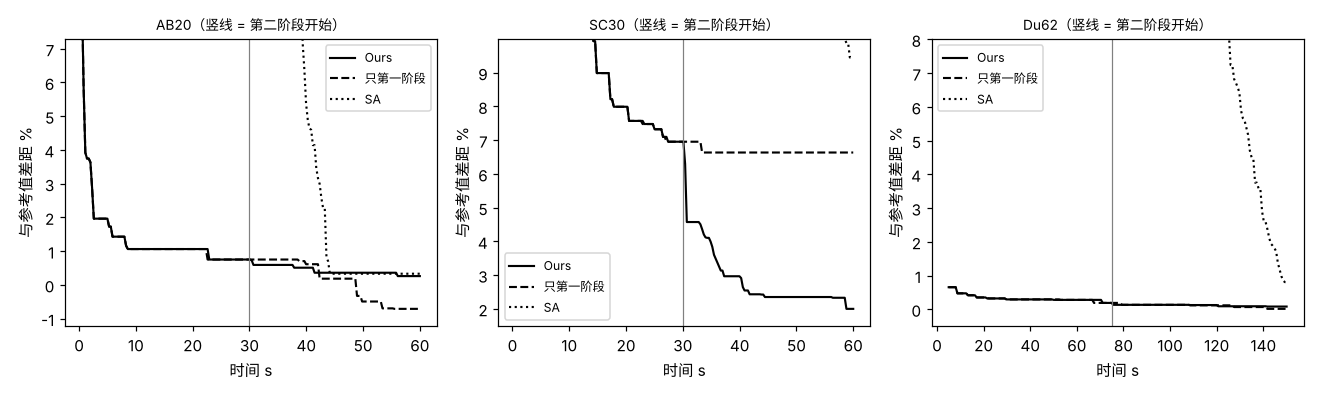

In [11]:
# 10 · 收敛曲线（中位数，10 个种子）/ anytime curves from the stored traces
def curve(runs, grid):
    M = []
    for r in runs:
        tr = r["meta"].get("trace") or []
        tr = [(t, c) for t, c in tr if c is not None]
        v = []; j = 0; best = np.nan
        for t in grid:
            while j < len(tr) and tr[j][0] <= t: best = tr[j][1]; j += 1
            v.append(best)
        M.append(v)
    import warnings
    with warnings.catch_warnings():
        warnings.simplefilter("ignore"); return np.nanmedian(np.array(M, float), axis=0)
fig, axs = plt.subplots(1, 3, figsize=(12, 3.6), dpi=110)
for ax, k in zip(axs, ["AB20", "SC30", "Du62"]):
    grid = np.linspace(0.5, BUDGET[k], 200)
    for m, ls, lab in [("ours", "-", "Ours"), ("ours_s1", "--", "只第一阶段"), ("sa", ":", "SA")]:
        y = curve(RUNS[(m, k)], grid); ax.plot(grid, 100*(y-REF[k])/REF[k], ls, color="black", lw=1.4, label=lab)
    ax.axvline(BUDGET[k]/2, color="gray", lw=0.8); ax.set_title(f"{k}（竖线 = 第二阶段开始）", fontsize=9)
    ax.set_xlabel("时间 s"); ax.set_ylabel("与参考值差距 %"); ax.legend(fontsize=8)
    lo = min(np.nanmin(100*(curve(RUNS[(m, k)], grid)-REF[k])/REF[k]) for m in ("ours", "ours_s1")); ax.set_ylim(lo - 0.5, lo + 8)
fig.tight_layout(); fig.savefig(f"{FIG}/anytime.png"); plt.close(fig); display(Image(f"{FIG}/anytime.png"))

## R6 + A · 消融实验 / Ablation
| 变体 | 文件名 | 改了什么 |
|---|---|---|
| Ours（完整） | `ours` | 第一阶段一半时间 + 精英池 4 个 + 第二阶段搜索（80% 近邻移动） |
| 只第一阶段 | `ours_s1` | 全部时间做切片树 SA |
| 第一阶段 + 抛光 | `ours_s2` | 全部时间切片树 SA，最后解一次 SOCP |
| 去掉第一阶段 | `ours_nos1` | 第二阶段从随机可行序列对开始 |
| 精英池 = 1 | `ours_noelite` | 只从第一阶段最好的一个布局开始搜索 |
| 均匀邻居 | `ours_unif` | 第二阶段移动对象均匀随机选（p_near = 0） |

In [12]:
# 11 · 消融全表（原始数据重算）/ ablation table recomputed from raw runs
VAR = [("ours", "Ours（完整）"), ("ours_noelite", "精英池 = 1"), ("ours_unif", "均匀邻居"),
       ("ours_s2", "第一阶段 + 抛光"), ("ours_s1", "只第一阶段"), ("ours_nos1", "去掉第一阶段")]
rows = []
for k in INST:
    for m, lab in VAR:
        rs = RUNS.get((m, k))
        if not rs: continue
        c = np.array([r["cost"] for r in rs if r["feasible"]])
        rows.append(dict(实例=k, 变体=lab, 可行=f"{len(c)}/{len(rs)}", 最好=c.min() if len(c) else np.nan,
                         平均=c.mean() if len(c) else np.nan, 标准差=c.std(ddof=1) if len(c) > 1 else np.nan,
                         平均差距=100*(c.mean()-REF[k])/REF[k] if len(c) else np.nan))
ABL = pd.DataFrame(rows)
display(ABL.round({"最好": 2, "平均": 2, "标准差": 2, "平均差距": 2}).set_index(["实例", "变体"]))

可行          最好          平均      标准差   平均差距
实例    变体                                                      
O7    Ours（完整）   10/10      131.65      131.65     0.00   0.00
      第一阶段 + 抛光  10/10      131.65      131.66     0.00   0.00
      只第一阶段      10/10      131.69      131.69     0.00   0.03
vC10a Ours（完整）   10/10    18522.79    18522.79     0.00  -0.00
      第一阶段 + 抛光  10/10    18522.79    18522.79     0.00  -0.00
      只第一阶段      10/10    18522.79    18522.79     0.00  -0.00
AB20  Ours（完整）   10/10     4949.54     5020.81    47.79  -0.01
      精英池 = 1    10/10     4861.35     5008.76    73.04  -0.25
      均匀邻居       10/10     4949.54     5022.71    54.48   0.03
      第一阶段 + 抛光  10/10     4926.92     5004.52    66.91  -0.33
      只第一阶段      10/10     4926.92     5000.64    61.49  -0.41
      去掉第一阶段     10/10     5313.70     5639.86   273.43  12.32
SC30  Ours（完整）   10/10     3301.27     3407.85    69.18   1.93
      精英池 = 1    10/10     3332.69     3411.51    51.91   2.04
      均匀邻居       10/10     3367.91     3426.57    44.31   2.49
      第一阶段 + 抛光  10/10     3372.80     3498.23    70.07   4.63
      只第一阶段      10/10     3475.55     3577.69    87.12   7.01
      去掉第一阶段     10/10     3308.88     3690.44   269.44  10.38
Du62  Ours（完整）   10/10  3629508.93  3637888.92  5454.26   0.07
      精英池 = 1    10/10  3629508.93  3637888.92  5454.26   0.07
      均匀邻居       10/10  3629508.93  3637888.92  5454.26   0.07
      第一阶段 + 抛光  10/10  3626553.92  3636281.42  5794.02   0.03
      只第一阶段      10/10  3626598.70  3636299.54  5794.90   0.03
      去掉第一阶段      0/10         NaN         NaN      NaN    NaN

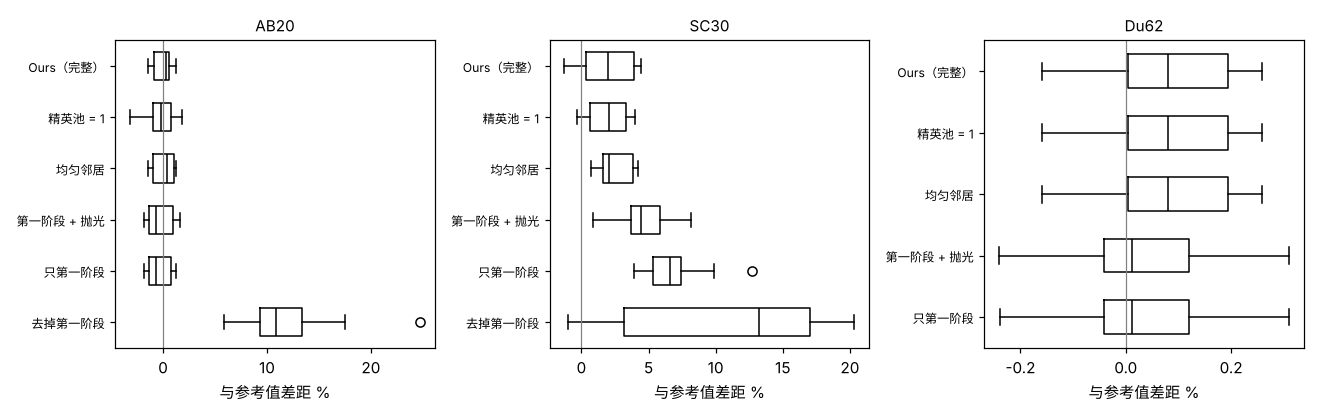

In [13]:
# 12 · 消融箱线图 / ablation box plots
fig, axs = plt.subplots(1, 3, figsize=(12, 3.8), dpi=110)
for ax, k in zip(axs, ["AB20", "SC30", "Du62"]):
    data, labs = [], []
    for m, lab in VAR:
        rs = RUNS.get((m, k))
        c = [100*(r["cost"]-REF[k])/REF[k] for r in rs if r["feasible"]] if rs else []
        if c: data.append(c); labs.append(lab)
    ax.boxplot(data, orientation="horizontal", widths=0.55, medianprops=dict(color="black"))
    ax.set_yticks(range(1, len(labs)+1), labs, fontsize=8); ax.invert_yaxis()
    ax.axvline(0, color="gray", lw=0.8); ax.set_title(k, fontsize=10); ax.set_xlabel("与参考值差距 %")
fig.tight_layout(); fig.savefig(f"{FIG}/ablation_box.png"); plt.close(fig); display(Image(f"{FIG}/ablation_box.png"))

In [14]:
# 13 · 显著性检验：Mann–Whitney U（双侧）+ Holm 校正，效应量 A12 / significance tests (recomputed)
from scipy.stats import mannwhitneyu
def costs(m, k, pol=None):
    if pol is not None:
        return None
    rs = RUNS.get((m, k)); return np.array([r["cost"] for r in rs if r["feasible"]]) if rs else np.array([])
POLC = {}
for k in INST:   # polish 后的每次成本（第 7 格算过的流程，这里保留每次的值）
    P = problem(k); S2 = from_problem(P)
    for m in ["sa", "cro"]:
        POLC[(m, k)] = np.array([evaluate(P.inst, [tuple(x) for x in polish(r["rects"], P, S2)])["cost"] for r in RUNS[(m, k)] if r["feasible"]])
CMP = [("swap", "Swap"), ("ga", "GA"), ("sa", "SA"), ("sa+p", "SA + polish"), ("cro", "CRO"), ("cro+p", "CRO + polish"),
       ("ours_s1", "只第一阶段"), ("ours_s2", "第一阶段 + 抛光")]
out = {}
for k in INST:
    a = costs("ours", k); ps = []
    for m, lab in CMP:
        b = POLC[(m[:-2], k)] if m.endswith("+p") else costs(m, k)
        if len(b) < 2: ps.append((lab, np.nan, np.nan)); continue
        if np.allclose(np.r_[a, b], a[0], rtol=1e-6): ps.append((lab, "tie", np.nan)); continue
        p = mannwhitneyu(a, b, alternative="two-sided").pvalue
        A12 = np.mean([(x < y) + 0.5*(x == y) for x in a for y in b])
        ps.append((lab, p, A12))
    # Holm 校正：和论文一样——tie 记 p = 1 并计入比较次数；可行次数不足两次的（n/a）不计入
    raw = {i: (1.0 if p == "tie" else p) for i, (_, p, _) in enumerate(ps) if p == "tie" or (isinstance(p, float) and not np.isnan(p))}
    order = sorted(raw, key=lambda i: raw[i]); m_ = len(raw); adj = {}; run = 0
    for r_, i in enumerate(order):
        run = max(run, min(1, (m_ - r_) * raw[i])); adj[i] = run
    out[k] = [("tie" if p == "tie" else "n/a" if not isinstance(p, float) or np.isnan(p) else f"{adj[i]:.2g} ({A12:.2f})")
              for i, (lab, p, A12) in enumerate(ps)]
display(pd.DataFrame(out, index=[lab for _, lab in CMP]).rename_axis("Ours vs"))
print("单元格 = Holm 校正后的 p（A12）；A12 > 0.5 表示 Ours 更好。tie = 20 个成本全部相同；n/a = 可行运行不足两次。")
# 和论文 tab_stats 对比
st = open(f"{PAPER}/tables/tab_stats.tex").read()
print("论文 tab_stats 原文（前 4 行）：")
for l in st.splitlines():
    if l.startswith(("Swap", "GA", "SA &", "SA +")): print(l)

,O7,vC10a,AB20,SC30,Du62
Ours vs,,,,,
Swap,0.00078 (1.00),0.0013 (1.00),0.0015 (1.00),0.0015 (1.00),n/a
GA,0.00078 (1.00),0.0013 (1.00),0.0015 (1.00),0.0015 (1.00),0.0013 (1.00)
SA,0.00076 (1.00),tie,1 (0.61),0.0023 (0.95),0.069 (0.82)
SA + polish,0.00078 (1.00),tie,1 (0.61),0.023 (0.84),0.069 (0.82)
CRO,0.00078 (1.00),tie,0.0015 (1.00),0.0015 (1.00),0.0013 (1.00)
CRO + polish,0.00078 (1.00),tie,0.0015 (1.00),0.0015 (1.00),0.0013 (1.00)
只第一阶段,0.00078 (1.00),tie,1 (0.39),0.0018 (0.97),1 (0.42)
第一阶段 + 抛光,0.00078 (1.00),tie,1 (0.41),0.023 (0.83),1 (0.41)


单元格 = Holm 校正后的 p（A12）；A12 > 0.5 表示 Ours 更好。tie = 20 个成本全部相同；n/a = 可行运行不足两次。
论文 tab_stats 原文（前 4 行）：
Swap & $\mathbf{7.8\cdot10^{-4}}$ (1.00) & $\mathbf{1.3\cdot10^{-3}}$ (1.00) & $\mathbf{1.5\cdot10^{-3}}$ (1.00) & $\mathbf{1.5\cdot10^{-3}}$ (1.00) & n/a \\
GA & $\mathbf{7.8\cdot10^{-4}}$ (1.00) & $\mathbf{1.3\cdot10^{-3}}$ (1.00) & $\mathbf{1.5\cdot10^{-3}}$ (1.00) & $\mathbf{1.5\cdot10^{-3}}$ (1.00) & $\mathbf{1.3\cdot10^{-3}}$ (1.00) \\
SA & $\mathbf{7.6\cdot10^{-4}}$ (1.00) & tie & 1 (0.61) & $\mathbf{2.3\cdot10^{-3}}$ (0.95) & 0.069 (0.82) \\
SA + polish & $\mathbf{7.8\cdot10^{-4}}$ (1.00) & tie & 1 (0.61) & \textbf{0.023} (0.84) & 0.069 (0.82) \\


## T · 主表复算 / Main table, recomputed

In [15]:
# 14 · 主表（每个方法 10 次运行；polish 行来自第 7 格）/ main table
ML = [("construct", "Construct"), ("swap", "Swap"), ("ga", "GA"), ("sa", "SA"), ("sa+p", "SA + polish"),
      ("cro", "CRO"), ("cro+p", "CRO + polish"), ("ours", "Ours")]
rows = []
for k in INST:
    for m, lab in ML:
        c = POLC[(m[:-2], k)] if m.endswith("+p") else costs(m, k)
        n_all = 10 if m != "construct" else 1
        rows.append(dict(实例=k, 方法=lab, 可行=f"{len(c)}/{n_all}", 最好=c.min(), 平均=c.mean(),
                         最好差距=100*(c.min()-REF[k])/REF[k], 平均差距=100*(c.mean()-REF[k])/REF[k]))
MAIN = pd.DataFrame(rows)
display(MAIN.round({"最好": 2, "平均": 2, "最好差距": 3, "平均差距": 3}).set_index(["实例", "方法"]))

可行          最好          平均     最好差距     平均差距
实例    方法                                                           
O7    Construct       1/1      151.07      151.07   14.747   14.747
      Swap          10/10      131.69      131.69    0.027    0.027
      GA            10/10      131.69      137.80    0.027    4.667
      SA            10/10      131.69      131.69    0.027    0.027
      SA + polish   10/10      131.65      131.66    0.000    0.003
      CRO           10/10      131.69      131.69    0.027    0.027
      CRO + polish  10/10      131.65      131.66    0.000    0.003
      Ours          10/10      131.65      131.65    0.000    0.000
vC10a Construct       1/1    28322.56    28322.56   52.907   52.907
      Swap          10/10    18522.79    18804.48   -0.000    1.521
      GA            10/10    19670.20    22007.37    6.195   18.812
      SA            10/10    18522.79    18522.79   -0.000   -0.000
      SA + polish   10/10    18522.79    18522.79   -0.000   -0.000
      CRO           10/10    18522.79    18522.79   -0.000   -0.000
      CRO + polish  10/10    18522.79    18522.79   -0.000   -0.000
      Ours          10/10    18522.79    18522.79   -0.000   -0.000
AB20  Construct       1/1     8824.29     8824.29   75.742   75.742
      Swap          10/10     5495.96     5573.29    9.456   10.996
      GA            10/10     5537.01     6216.97   10.273   23.815
      SA            10/10     4926.92     5043.20   -1.877    0.439
      SA + polish   10/10     4926.92     5043.20   -1.877    0.439
      CRO           10/10     5123.24     5291.01    2.033    5.374
      CRO + polish  10/10     5123.24     5291.01    2.033    5.374
      Ours          10/10     4949.54     5020.81   -1.426   -0.007
SC30  Construct       1/1     9880.40     9880.40  195.513  195.513
      Swap          10/10     4386.11     4534.38   31.184   35.619
      GA            10/10     4632.73     5124.95   38.560   53.282
      SA            10/10     3469.66     3646.64    3.774    9.068
      SA + polish   10/10     3381.58     3534.20    1.140    5.704
      CRO           10/10     3734.94     4311.81   11.709   28.962
      CRO + polish  10/10     3528.51     4126.31    5.534   23.414
      Ours          10/10     3301.27     3407.85   -1.262    1.926
Du62  Construct       1/1  4684133.69  4684133.69   28.851   28.851
      Swap           1/10  4023859.84  4023859.84   10.688   10.688
      GA            10/10  3696431.38  3735359.99    1.681    2.752
      SA            10/10  3623772.52  3666052.33   -0.317    0.846
      SA + polish   10/10  3623751.81  3666030.22   -0.318    0.845
      CRO           10/10  3678297.88  3700566.61    1.183    1.795
      CRO + polish  10/10  3678291.91  3700540.99    1.182    1.794
      Ours          10/10  3629508.93  3637888.92   -0.160    0.071

In [16]:
# 15 · 和论文表逐格对比 / compare with the paper table cell by cell
tab = open(f"{PAPER}/tables/tab_main.tex").read()
num = lambda s: float(s.replace("{,}", "").replace("$-$", "-").replace("\\textbf{", "").replace("}", "").split("$")[0].strip())
paper = {}
for blk in re.split(r"\\multicolumn\{6\}\{l\}\{\\textit\{", tab)[1:]:
    name = blk.split("}")[0]
    for l in blk.splitlines():
        l = l.strip()
        if not l.startswith("\\quad"): continue
        f = [x.strip() for x in l.replace("\\quad", "").rstrip("\\").split("&")]
        if "--" in f[2]: continue
        paper[(name, f[0])] = (num(f[2]), num(f[3]))
chk = []
for _, r in MAIN.iterrows():
    p = paper.get((r["实例"], r["方法"]))
    if p is None: continue
    db = abs(r["最好"] - p[0]) / p[0]; dm = abs(r["平均"] - p[1]) / p[1]
    chk.append(dict(实例=r["实例"], 方法=r["方法"], 论文最好=p[0], 重算最好=round(r["最好"], 4), 论文平均=p[1], 重算平均=round(r["平均"], 4),
                    一致="是" if max(db, dm) < 5e-6 else f"差 {100*max(db, dm):.4f}%"))
CHK = pd.DataFrame(chk)
print("逐格比较的行数:", len(CHK), "| 完全一致:", (CHK["一致"] == "是").sum())
display(CHK[CHK["一致"] != "是"] if (CHK["一致"] != "是").any() else CHK.head(3))

逐格比较的行数: 40 | 完全一致: 40


,实例,方法,论文最好,重算最好,论文平均,重算平均,一致
0,O7,Construct,151.0684,151.0684,151.0684,151.0684,是
1,O7,Swap,131.6892,131.6892,131.6892,131.6892,是
2,O7,GA,131.6892,131.6892,137.7969,137.7969,是


## 结论 / What the evidence supports
由上面的格子得出（不是另加的判断）：
1. **R1**：网格 CP-SAT 在 O7、Du62 上格子数不够，按构造不可行；300 s MINLP 只在 O7 上到最优。→ 核心用启发式搜索。
2. **R2–R3**：切片树让面积按比例分配、厂房铺满、不重叠天然成立，但 O7 上所有切片类方法都停在 131.6892（差 0.027%）。→ 需要能表示非切片布局的第二阶段。
3. **R4**：给定序列对，SOCP 精确求几何；一次 SOCP 就把 O7 从 131.6892 推到 131.6532（已证明最优）。重算的 polish 行见第 7 格、与论文对比见第 15 格。
4. **R5**：第二阶段搜索的收益集中在 SC30；Du62 因 SOCP 太慢按规则只抛光。
5. **消融**：去掉第一阶段在 AB20、SC30 上差 10% 以上、Du62 无可行解；精英池和近邻移动没有可测出的作用；AB20、Du62 上"只第一阶段"的平均不比完整方法差。